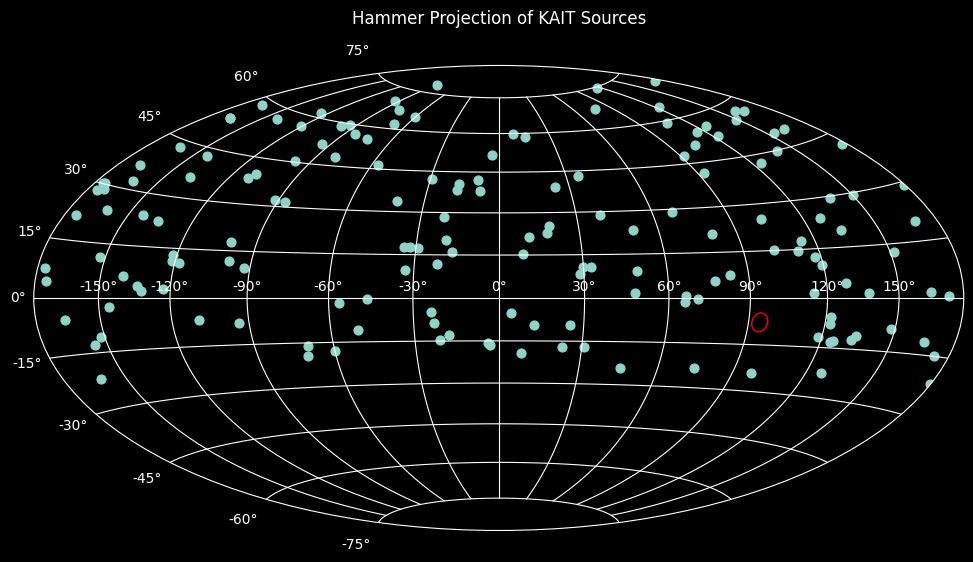

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord


# 1. Read the source file
df = pd.read_csv("KAIT.txt")


# 2. Convert the RA and Dec strings to coordinates
coords = SkyCoord(
    df["Right_Ascension"],
    df["Declination"],
    frame="icrs"
)


# 3. Get RA and Dec in degrees
ra_deg = coords.ra.degree
dec_deg = coords.dec.degree


# 4. Convert degrees to radians
ra_rad = np.radians(ra_deg)
dec_rad = np.radians(dec_deg)


# 5. Wrap RA from 0–360 degrees into -180–180 degrees
ra_rad = np.remainder(ra_rad + 2*np.pi, 2*np.pi)

ra_rad[ra_rad > np.pi] -= 2*np.pi



# 7. Make the Hammer projection
fig = plt.figure(figsize=(12, 7))

ax = fig.add_subplot(111, projection="hammer")


# 8. Plot the sources
ax.scatter(
    ra_rad,
    dec_rad,
    s=40
)


# 9. Add grid and title
ax.grid(True)

ax.set_title(
    "Hammer Projection of KAIT Sources",
    pad=30
)

center_ra_deg = 94.3
center_dec_deg = -7.8
radius_deg = 3

theta = np.linspace(0, 2 * np.pi, 300)

circle_ra_deg = center_ra_deg + radius_deg * np.cos(theta) / np.cos(np.radians(center_dec_deg))
circle_dec_deg = center_dec_deg + radius_deg * np.sin(theta)

circle_ra_plot_deg = (circle_ra_deg + 180) % 360 - 180
circle_ra_rad = np.radians(circle_ra_plot_deg)
circle_dec_rad = np.radians(circle_dec_deg)

ax.plot(circle_ra_rad, circle_dec_rad, color="red", linewidth=1)

plt.show()

In [10]:
from astropy.coordinates import SkyCoord
import astropy.units as u

center = SkyCoord(ra=94.3*u.deg, dec=-7.8*u.deg)

separation = coords.separation(center)

inside = df[separation.deg <= 3]

print("Sources inside 3 degrees:", len(inside))
print(inside)

Sources inside 3 degrees: 0
Empty DataFrame
Columns: [Source_Name, Right_Ascension, Declination]
Index: []
